# OrbitML

Un TLE (Two-Line Element) est une orbite approximative. Propagé avec le modèle SGP4, il prédit la position d'un satellite avec une erreur de l'ordre du kilomètre, et cette erreur grandit. Or cette erreur n'est pas du bruit : elle a une structure. Peng & Bai (2018) proposent de l'apprendre (avec un modèle), puis de la retrancher de la prédiction SGP4.

Pour mesurer l'erreur de SGP4, il faut connaître la vraie position du satellite. On utilise les orbites précises (POE) de Sentinel-6A, calculées par le CNES, avec une précision de l'ordre du centimètre. On a choisi Sentinel-6A parce qu'il fait très peu de manœuvres (4 en 2024).

## Étape 1 : la vérité

Les orbites précises de Sentinel-6A sont dans `data/sp3/s6a/`, au format SP3, un format texte standard. Chaque fichier est compressé en `.Z`. Le module `gzip` de Python ne sait pas le lire, mais la commande `gzip -dc` le décompresse très bien.

Voici à quoi ressemble un fichier une fois décompressé :

```
#cV2023 12 13  3 21  0.00000000   14308 ORBIT ITRF  FIT CNES      <- date de début, 14308 états, repère ITRF
## 2292 271260.00000000    60.00000000 ...                        <- semaine GPS, pas de temps = 60 s
%c L  cc TAI ...                                                  <- échelle de temps : TAI
...
*  2023 12 13  3 21  0.00000000                                   <- une date
PL40  3468.7606188  -817.1050730 -6844.2029489 999999.999999      <- position x, y, z en km
VL40-15613.8151346 65922.4868150-15775.4078392 999999.999999      <- vitesse vx, vy, vz en dm/s
*  2023 12 13  3 22  0.00000000
...
```

Quelques remarques :

- Le repère est l'ITRF, un repère qui tourne avec la Terre. SGP4, lui, donne des positions dans TEME. Il faudra convertir l'un dans l'autre
- Les dates sont en TAI, pas en UTC.
- Les vitesses sont en dm/s. On les divise par 10⁴ pour avoir des km/s.
- Un fichier couvre environ 10 jours, avec un état par minute.

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from astropy.coordinates import ITRS, TEME, CartesianRepresentation
from astropy.time import Time
from sgp4.api import Satrec

On lit un seul fichier pour commencer. Pour chaque date (ligne `*`), on garde la position (ligne `P`) et la vitesse (ligne `V`).

In [2]:
path = Path("data/sp3/s6a/ssas6a30.b24001.e24011.DG_.sp3.001.Z")
lines = subprocess.run(["gzip", "-dc", path], capture_output=True, text=True, check=True).stdout.splitlines()

dates, r, v = [], [], []
for line in lines:
    if line.startswith("*"):
        # "*  2023 12 13  3 21  0.00000000" -> année, mois, jour, heure, minute, seconde
        dates.append([float(x) for x in line[1:].split()])
    elif line.startswith("P"):
        r.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])
    elif line.startswith("V"):
        v.append([float(line[4:18]), float(line[18:32]), float(line[32:46])])

dates = np.array(dates)
year, month, day, hour, minute = dates[:, :5].astype(int).T  # astropy veut des entiers ici
time = Time(
    {"year": year, "month": month, "day": day, "hour": hour, "minute": minute, "second": dates[:, 5]},
    format="ymdhms", scale="tai",
)
r = np.array(r)          # km, ITRF
v = np.array(v) / 1e4    # dm/s -> km/s, ITRF

print(len(time), "états, de", time[0].utc.iso, "à", time[-1].utc.iso, "UTC")
print("pas de temps :", np.unique(np.diff(time.unix)), "s")
print("r :", r.shape, " v :", v.shape)

14308 états, de 2024-01-01 23:17:23.000 à 2024-01-11 21:44:23.000 UTC
pas de temps : [60.] s
r : (14308, 3)  v : (14308, 3)


La distance au centre de la Terre moins le rayon terrestre (6378 km à l'équateur) doit redonner l'altitude annoncée de Sentinel-6A, environ 1336 km.

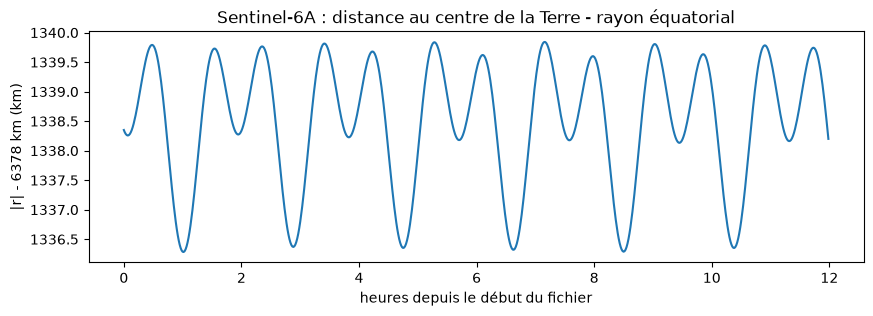

|r| - 6378 km : de 1336.2 à 1339.9 km sur tout le fichier


In [3]:
EARTH_RADIUS = 6378.137  # km, rayon équatorial

distance = np.linalg.norm(r, axis=1)
hours = (time - time[0]).to_value("hour")
first = hours < 12

plt.figure(figsize=(10, 3))
plt.plot(hours[first], distance[first] - EARTH_RADIUS)
plt.xlabel("heures depuis le début du fichier")
plt.ylabel("|r| - 6378 km (km)")
plt.title("Sentinel-6A : distance au centre de la Terre - rayon équatorial")
plt.show()

print(f"|r| - 6378 km : de {distance.min() - EARTH_RADIUS:.1f} à {distance.max() - EARTH_RADIUS:.1f} km sur tout le fichier")

On retrouve environ 1338 km, et la distance au centre ne varie que de ±2 km : l'orbite est presque circulaire.

Attention, cette courbe montre le rayon de l'orbite et non l'altitude au-dessus du sol. La Terre est aplatie (le rayon polaire fait 21 km de moins que le rayon équatorial), donc l'altitude réelle varie beaucoup plus que ces ±2 km.

On trace les 6 premières heures, soit environ 3 révolutions.

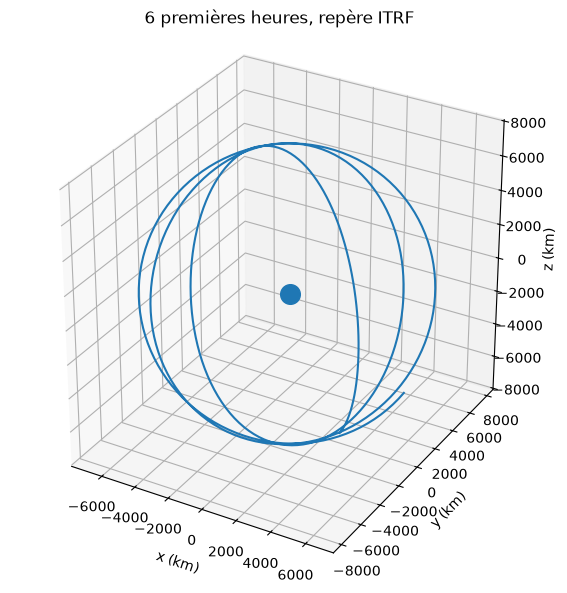

In [4]:
first = hours < 6

ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.plot(*r[first].T)
ax.scatter(0, 0, 0, color="tab:blue", s=200)  # la Terre, pas à l'échelle
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")
ax.set_aspect("equal")
ax.set_title("6 premières heures, repère ITRF")
plt.show()

L'orbite ne se referme pas : chaque révolution est décalée par rapport à la précédente. Ce n'est pas le satellite qui dérive, c'est le repère : l'ITRF tourne avec la Terre, d'environ 28° pendant une révolution.

## Étape 2 : SGP4

Les TLE de Sentinel-6A sont dans `data/tle/`. On n'en a qu'à partir de 2024, c'est pour ça qu'on lit le fichier SP3 du 1er janvier 2024 à l'étape 1. Un TLE tient sur deux lignes :

```
1 46984U 20086A   24001.60261332 -.00000054  00000-0  31477-4 0  9993     <- date du TLE : 2024, jour 1.6026
2 46984  66.0389 199.3442 0007637 269.6041  90.4099 12.80929714145361     <- inclinaison, nœud, excentricité 0.0007637, ..., 12.8 révolutions par jour
```

Pour l'instant, on prend juste le premier TLE du fichier.

In [5]:
tle = Path("data/tle/46984_2024-01-01_2025-01-02.tle").read_text().splitlines()
satellite = Satrec.twoline2rv(tle[0], tle[1])
tle_date = Time(satellite.jdsatepoch, satellite.jdsatepochF, format="jd", scale="utc")

print("date du TLE :", tle_date.iso, "UTC")

date du TLE : 2024-01-01 14:27:45.791 UTC


SGP4 donne la position en TEME, en km, aux dates qu'on lui demande (en UTC). On lui demande les dates du SP3, à partir de la date du TLE.

In [6]:
after = time >= tle_date
error, r_sgp4, v_sgp4 = satellite.sgp4_array(time[after].utc.jd1, time[after].utc.jd2)

print("codes d'erreur :", np.unique(error))  # 0 = tout va bien
print("r_sgp4 :", r_sgp4.shape)

codes d'erreur : [0]
r_sgp4 : (14308, 3)


Pour comparer, on passe la vérité de l'ITRF au TEME avec astropy.

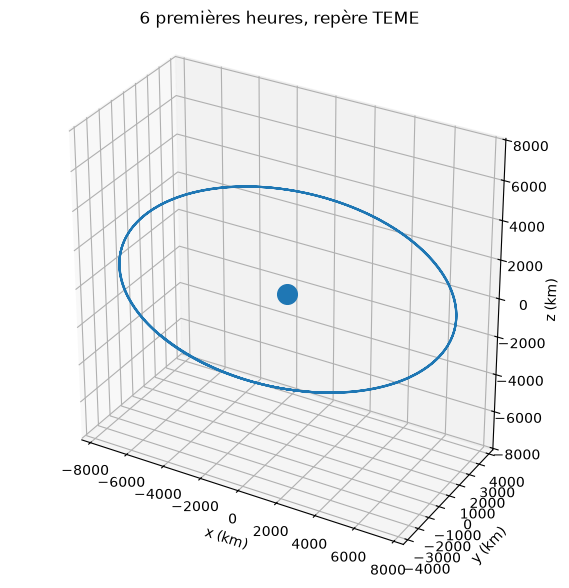

In [7]:
itrs = ITRS(CartesianRepresentation(r[after].T * u.km), obstime=time[after])
r_true = itrs.transform_to(TEME(obstime=time[after])).cartesian.xyz.to_value(u.km).T

ax = plt.figure(figsize=(7, 7)).add_subplot(projection="3d")
ax.plot(*r_true[:360].T)  # 360 états de 60 s = 6 h
ax.scatter(0, 0, 0, color="tab:blue", s=200)
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")
ax.set_aspect("equal")
ax.set_title("6 premières heures, repère TEME")
plt.show()

Cette fois, l'orbite se referme : TEME ne tourne pas avec la Terre. Les deux positions sont maintenant dans le même repère, on peut regarder la distance entre elles.

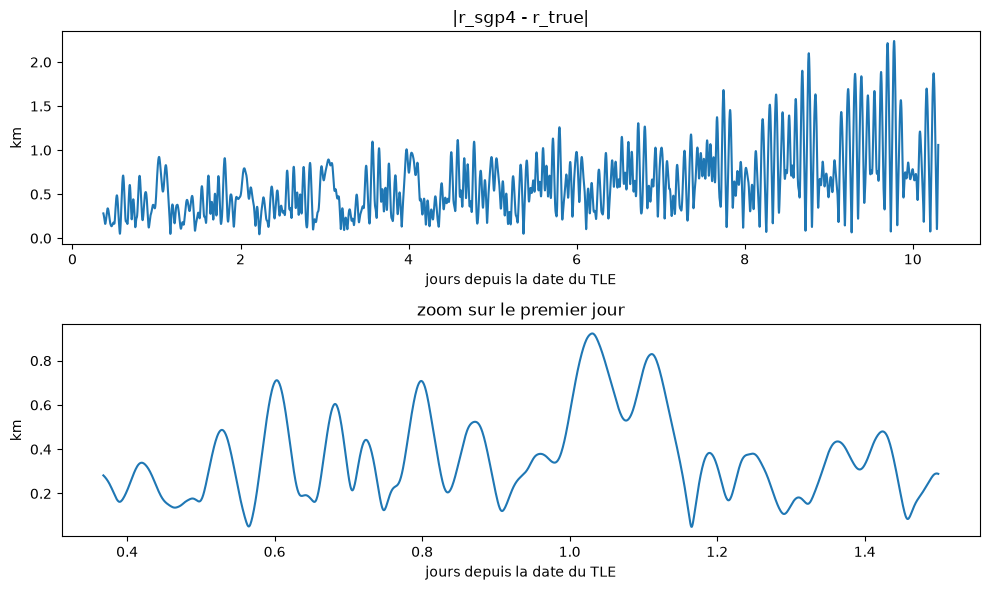

In [8]:
days = (time[after] - tle_date).to_value("day")
distance = np.linalg.norm(r_sgp4 - r_true, axis=1)
first = days < 1.5

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6))
top.plot(days, distance)
top.set_title("|r_sgp4 - r_true|")
bottom.plot(days[first], distance[first])
bottom.set_title("zoom sur le premier jour")
for ax in (top, bottom):
    ax.set_xlabel("jours depuis la date du TLE")
    ax.set_ylabel("km")
fig.tight_layout()
plt.show()

L'erreur part d'environ 300 m et monte jusqu'à environ 2 km au bout de 10 jours. Elle n'est pas aléatoire : elle oscille au rythme des révolutions et son amplitude grandit. C'est cette structure qu'on voudra apprendre.